
1. RX AUDIO CHAIN OPTIMIZATION (20m JLCPCB Build -> 40m Tayloe 2x Add-On)
JLCPCB 20m Audio Filter BOM (Identical for 40m):
  c_ac  (AC-coupling capacitor          ):      10u [X5R]
  r_in  (Diff-amp input resistor        ):       1k [R1pct]
  r_fb  (Diff-amp feedback resistor     ):      50k [R1pct]
  c_fb  (Diff-amp feedback cap (pole 1) ):     200p [C0G]
  ra    (Sallen-Key R (both resistors)  ):    12.4k [R1pct]
  ca    (Sallen-Key Ca (feedback cap)   ):     1.6n [C0G]
  cb    (Sallen-Key Cb (cap to ground)  ):     620p [C0G]

Tayloe Integration Capacitors (Band-Specific):
  20m JLCPCB Build : 1x 2.2nF per I/Q branch (+ 1x DNP parallel footprint)
  40m Hand Add-On  : Solder +1x 2.2nF in parallel -> 4.4nF total
   (2.2 nF Tayloe)] 128-Corner Worst-Case -> Alias: -66.84 dB (limit -66.52) | Passband droop: 0.261 dB | fc_min: 10.94 kHz | Q: 0.764..0.844 -> PASS
   (4.4 nF Tayloe = 2x)] 128-Corner Worst-Case -> Alias: -67.08 dB (limit -66.52) | Passband droop: 0.261 dB | fc_min: 10.94 k

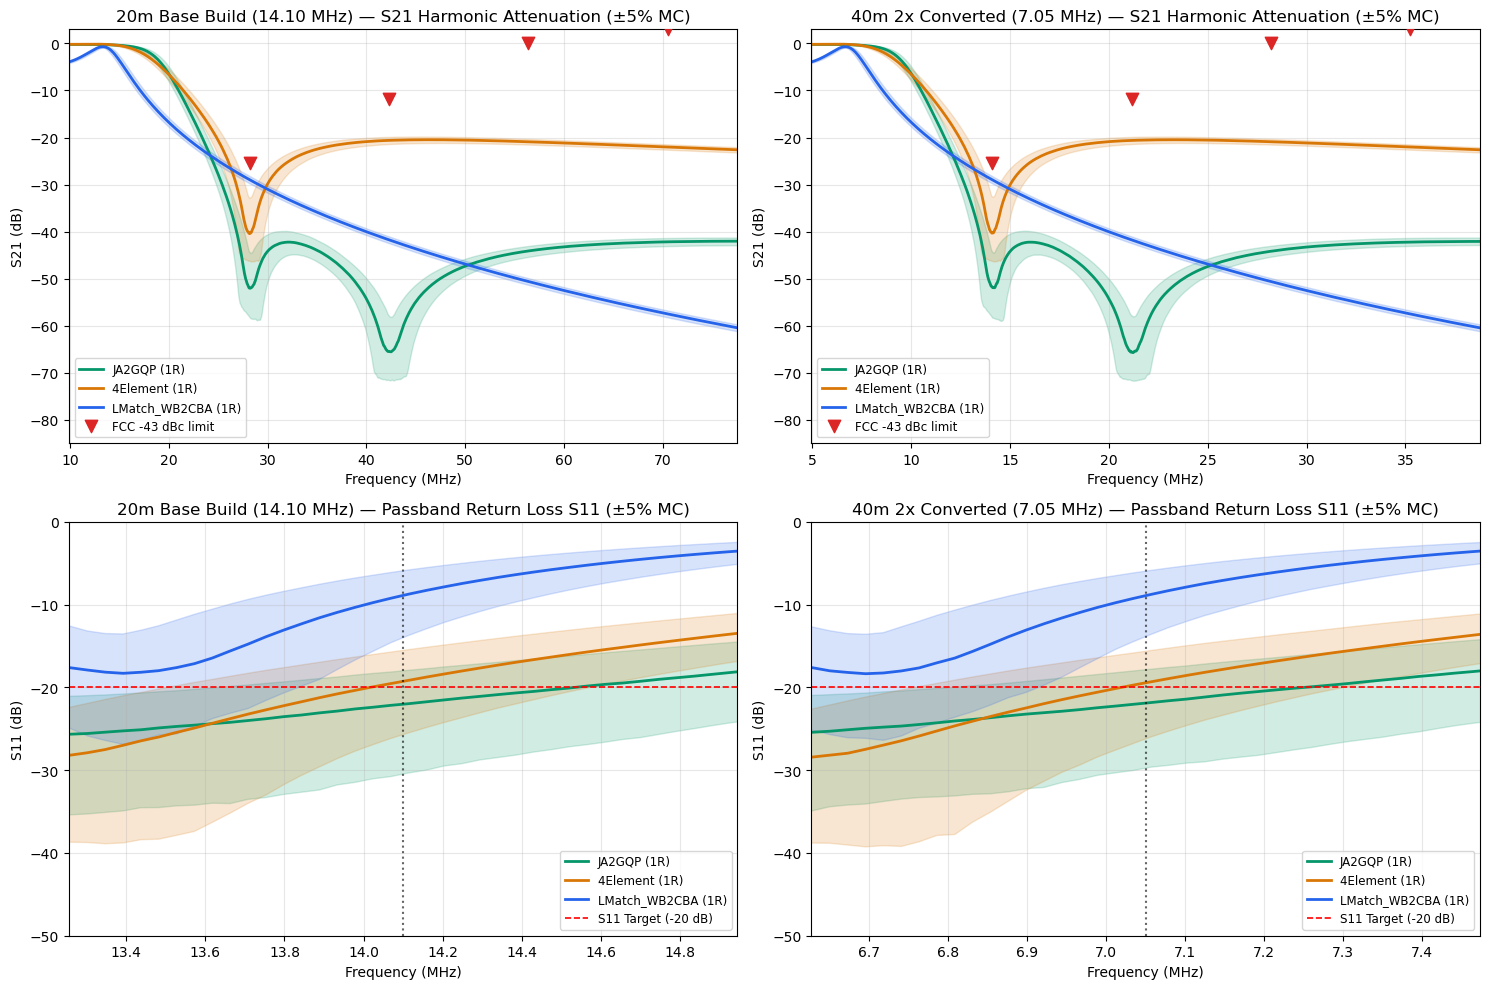

In [1]:
# ==============================================================================
# UNIFIED TRX FRONTEND & AUDIO CHAIN OPTIMIZER (20m JLCPCB Build -> 40m Add-On)
# Part 1: Arch A RX Audio Anti-Aliasing & Tayloe Detector (20m & 40m Verified)
# Part 2: Joint 20m / 40m TX Harmonic LPF (1-Reel, Exact 2x Component Doubling)
# ==============================================================================
import itertools
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import firwin, freqz
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
from scipy.special import erfinv


# ==============================================================================
# 0. SHARED E-SERIES POOLS & UTILITIES
# ==============================================================================
E24 = np.array([
    1.0, 1.1, 1.2, 1.3, 1.5, 1.6, 1.8, 2.0, 2.2, 2.4, 2.7, 3.0,
    3.3, 3.6, 3.9, 4.3, 4.7, 5.1, 5.6, 6.2, 6.8, 7.5, 8.2, 9.1,
])
E12 = E24[::2]
E96 = np.round(10 ** (np.arange(96) / 96), 2)

SERIES = {"E12": E12, "E24": E24, "E96": E96}


def expand_series(series_name, decade_mults, vmin=0.0, vmax=np.inf):
    arr = np.sort(np.concatenate([SERIES[series_name] * d for d in decade_mults]))
    return arr[(arr >= vmin) & (arr <= vmax)]


def fmt_eng(v, unit=""):
    if v >= 1e6:
        return f"{v/1e6:.4g}M{unit}"
    if v >= 1e3:
        return f"{v/1e3:.4g}k{unit}"
    if v >= 1.0:
        return f"{v:.4g}{unit}"
    if v >= 1e-3:
        return f"{v*1e3:.4g}m{unit}"
    if v >= 1e-6:
        return f"{v*1e6:.4g}u{unit}"
    if v >= 1e-9:
        return f"{v*1e9:.4g}n{unit}"
    return f"{v*1e12:.4g}p{unit}"


def section(title):
    print("\n" + "=" * 86)
    print(title)
    print("=" * 86)


# ==============================================================================
# PART 1: RX AUDIO CHAIN (TAYLOE MIXER + ARCH A ACTIVE FILTER + ADC + CIC/FIR)
# ==============================================================================
FS, FS1, FS2, FSOUT = 192e3, 48e3, 24e3, 8e3
SSB = 2.7e3
FCRIT = FS - FSOUT / 2
FCRIT_HI = FS + FSOUT / 2

BLOCKER_DBFS = -30.0
ALIAS_BELOW_NOISE_DB = 10.0
ADC_SNR_TYP = 68.0
ADC_VREF, ADC_BITS = 3.10, 12
ADC_SNR_NOISE_DBFS = -ADC_SNR_TYP - 10 * np.log10(FS / SSB)
ALIAS_THRESHOLD_DBFS = ADC_SNR_NOISE_DBFS - ALIAS_BELOW_NOISE_DB
TARGET_ALIAS_DB = -(BLOCKER_DBFS - ALIAS_THRESHOLD_DBFS)  # -66.52 dB
MAX_PASS_LOSS_DB = 0.5
Q_MIN, Q_MAX = 0.60, 0.85

# Tayloe Mixer (20m = 1x 2.2 nF; 40m = 2x 2.2 nF in parallel = 4.4 nF)
R_SOURCE_RF, R_ON_TAYLOE = 8.22, 5.0
R_SOURCE_AUDIO = 4 * (R_SOURCE_RF + R_ON_TAYLOE)
C_TAYLOE_20M = 2.2e-9
C_TAYLOE_40M = 2 * C_TAYLOE_20M  # 4.4 nF via parallel DNP pad

# ADC Kickback & Acquisition
C_ADC, R_ADC_SWITCH, T_ACQ = 6e-12, 0.0, 2600e-9
R_KICK, C_KICK = 100.0, 1e-9
SETTLE_LIMIT = 0.5 / 2**ADC_BITS

PASSIVE_MODEL = {
    "C0G": (0.05, 0.99),
    "C0G1": (0.01, 0.99),
    "X5R": (0.20, 0.95),
    "R1pct": (0.01, 0.99),
}
CAP_CLASSES = {"C0G": 0.0, "C0G1": 0.50}
PAR_COST = 0.04


def tol(cls):
    return PASSIVE_MODEL[cls][0]


def draw_by_class(rng, cls, n, dist="truncnorm"):
    t, y = PASSIVE_MODEL[cls]
    if dist == "uniform":
        return rng.uniform(1 - t, 1 + t, n)
    sigma = t / (np.sqrt(2) * erfinv(y))
    out, filled = np.empty(n), 0
    while filled < n:
        s = rng.normal(0, sigma, n - filled)
        s = s[np.abs(s) <= t]
        out[filled : filled + len(s)] = 1 + s
        filled += len(s)
    return out


def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-15))


def wrap(f, fs):
    return (np.asarray(f) + fs / 2) % fs - fs / 2


def tayloe_resp(f, c_tayloe):
    fc_t = 1.0 / (2 * np.pi * R_SOURCE_AUDIO * c_tayloe)
    return 1.0 / (1.0 + 1j * np.asarray(f) / fc_t)


def arch_a(f, c_ac, r_in, r_fb, c_fb, ra, ca, cb):
    s = 2j * np.pi * np.asarray(f, float)
    r_tot = r_in + R_SOURCE_AUDIO
    H_hp = s * r_tot * c_ac / (1 + s * r_tot * c_ac)
    H_p1 = 1 / (1 + s * r_fb * c_fb)
    w0 = 1 / (ra * np.sqrt(ca * cb))
    Q = np.sqrt(ca / cb) / 2
    H_sk = w0**2 / (s**2 + s * w0 / Q + w0**2)
    return H_hp * H_p1 * H_sk


HB = firwin(63, 12e3, fs=FS1)
POLY = firwin(161, 3.35e3, fs=FS2)


def cic(f):
    f = np.asarray(f, float)
    den = 4 * np.sin(np.pi * f / FS)
    num = np.sin(4 * np.pi * f / FS)
    ratio = np.ones_like(f)
    m = np.abs(den) > 1e-12
    ratio[m] = num[m] / den[m]
    return np.abs(ratio) ** 4


def fir_response(f, coeff, fs):
    _, h = freqz(coeff, worN=2 * np.pi * np.asarray(f) / fs)
    return np.abs(h)


def digital_chain(f):
    f = np.asarray(f, float)
    return (
        cic(wrap(f, FS))
        * fir_response(wrap(f, FS1), HB, FS1)
        * fir_response(wrap(f, FS2), POLY, FS2)
    )


RX_NAMES = ["c_ac", "r_in", "r_fb", "c_fb", "ra", "ca", "cb"]
RX_OPT = ["c_fb", "ra", "ca", "cb"]
RX_CAPS = {"c_ac", "c_fb", "ca", "cb"}
RX_SIGNS = np.array(list(itertools.product((-1, 1), repeat=len(RX_NAMES))))

RX_ROLE = {
    "c_ac": "AC-coupling capacitor",
    "r_in": "Diff-amp input resistor",
    "r_fb": "Diff-amp feedback resistor",
    "c_fb": "Diff-amp feedback cap (pole 1)",
    "ra": "Sallen-Key R (both resistors)",
    "ca": "Sallen-Key Ca (feedback cap)",
    "cb": "Sallen-Key Cb (cap to ground)",
}

VAL0 = dict(c_ac=10e-6, r_in=1e3, r_fb=50e3, c_fb=220e-12, ra=10e3, ca=1.5e-9, cb=750e-12)
CLS0 = dict(c_ac="X5R", r_in="R1pct", r_fb="R1pct", c_fb="C0G", ra="R1pct", ca="C0G", cb="C0G")
LBL0 = {n: fmt_eng(VAL0[n]) for n in RX_NAMES}

F_A = np.linspace(FCRIT, FCRIT_HI, 401)
F_P = np.linspace(300, SSB, 120)
F_FC = np.logspace(3, 5, 1500)

RX_CAP_POOL = expand_series("E24", (1e-12, 10e-12, 100e-12, 1e-9), 47e-12, 10e-9)
RX_R_POOL = expand_series("E96", (1e3, 10e3), 4e3, 30e3)


def _fc_from(H):
    below = H <= -3.0103
    has = below.any(axis=1)
    i = np.clip(below.argmax(axis=1), 1, None)[:, None]
    h0 = np.take_along_axis(H, i - 1, 1)[:, 0]
    h1 = np.take_along_axis(H, i, 1)[:, 0]
    l0, l1 = np.log(F_FC[i[:, 0] - 1]), np.log(F_FC[i[:, 0]])
    fc = np.exp(l0 + (-3.0103 - h0) / (h1 - h0 + 1e-30) * (l1 - l0))
    return np.where(has, fc, 0.0)


def rx_metrics_vec(x, c_tayloe=C_TAYLOE_20M):
    da = tayloe_resp(F_A, c_tayloe) * digital_chain(F_A)
    dp = tayloe_resp(F_P, c_tayloe) * digital_chain(F_P)
    xc = {k: np.asarray(v, float)[:, None] for k, v in x.items()}
    alias = db(da * arch_a(F_A, **xc)).max(axis=1)
    pas = np.abs(db(dp * arch_a(F_P, **xc))).max(axis=1)
    H = db(arch_a(F_FC, **xc)) - db(arch_a(np.array([100.0]), **xc))
    return alias, pas, _fc_from(H)


def rx_worst_case(val, cls, c_tayloe=C_TAYLOE_20M):
    t = np.array([tol(cls[n]) for n in RX_NAMES])
    v = np.array([val[n] for n in RX_NAMES])
    X = v * (1 + RX_SIGNS * t)
    x = {n: X[:, i] for i, n in enumerate(RX_NAMES)}
    a, p, fc = rx_metrics_vec(x, c_tayloe=c_tayloe)
    q = np.sqrt(x["ca"] / x["cb"]) / 2
    return a.max(), p.max(), fc.min(), q.min(), q.max()


def rx_verify(val, cls, c_tayloe=C_TAYLOE_20M):
    a, p, fc, qlo, qhi = rx_worst_case(val, cls, c_tayloe=c_tayloe)
    viol = (
        max(0, a - TARGET_ALIAS_DB)
        + max(0, p - MAX_PASS_LOSS_DB)
        + max(0, Q_MIN - qlo)
        + max(0, qhi - Q_MAX)
    )
    return viol, fc, a, p


def rx_build_candidates(name, center, window=0.35, max_par=1, cap_classes=None):
    lo, hi = center * (1 - window), center * (1 + window)
    if name == "ra":
        combos = [(v, fmt_eng(v), 1) for v in RX_R_POOL if lo <= v <= hi]
        classes = {"R1pct": 0.0}
    else:
        combos = [(v, fmt_eng(v), 1) for v in RX_CAP_POOL if lo <= v <= hi]
        if max_par >= 2:
            for i, a in enumerate(RX_CAP_POOL):
                for b in RX_CAP_POOL[i:]:
                    if lo <= a + b <= hi:
                        combos.append((a + b, f"{fmt_eng(a)}+{fmt_eng(b)}", 2))
        classes = cap_classes or CAP_CLASSES
    return [
        dict(v=v, label=l, cls=c, tol=tol(c), cost=k + PAR_COST * (n - 1))
        for v, l, n in combos
        for c, k in classes.items()
    ]


def rx_jacobian(val, eps=1e-3):
    k = len(RX_NAMES)
    X = {n: np.full(2 * k, val[n], float) for n in RX_NAMES}
    for i, n in enumerate(RX_NAMES):
        X[n][i] *= np.exp(eps)
        X[n][k + i] *= np.exp(-eps)
    a, p, fc = rx_metrics_vec(X, c_tayloe=C_TAYLOE_20M)
    m = np.column_stack([a, p, fc / 1e3])
    return (m[:k] - m[k:]) / (2 * eps)


def rx_solve_step(val, cls, cands, delta, margin, cost_w=0.02, slack_w=1e3):
    J = rx_jacobian(val)
    a0, p0, fc0 = rx_metrics_vec({n: [val[n]] for n in RX_NAMES}, c_tayloe=C_TAYLOE_20M)
    m0 = np.array([a0[0], p0[0], fc0[0] / 1e3])
    ix = {n: i for i, n in enumerate(RX_NAMES)}
    sel = {n: [c for c in cands[n] if abs(np.log(c["v"] / val[n])) <= delta] for n in RX_OPT}
    if any(not sel[n] for n in RX_OPT):
        return None

    off, cur = {}, 0
    for n in RX_OPT:
        off[n] = cur
        cur += len(sel[n])
    nv = cur + 2
    i_sa, i_sp = cur, cur + 1

    c = np.zeros(nv)
    c[[i_sa, i_sp]] = slack_w
    for n in RX_OPT:
        for k, cd in enumerate(sel[n]):
            dx = np.log(cd["v"] / val[n])
            c[off[n] + k] = -(J[ix[n], 2] * dx - abs(J[ix[n], 2]) * cd["tol"]) + cost_w * cd["cost"]

    rows, lo, hi = [], [], []
    for n in RX_OPT:
        r = np.zeros(nv)
        r[off[n] : off[n] + len(sel[n])] = 1
        rows.append(r); lo.append(1); hi.append(1)

    fixed = [n for n in RX_NAMES if n not in RX_OPT]
    for mi, slack, limit in ((0, i_sa, TARGET_ALIAS_DB - margin), (1, i_sp, MAX_PASS_LOSS_DB - 0.5 * margin)):
        r = np.zeros(nv)
        for n in RX_OPT:
            for k, cd in enumerate(sel[n]):
                dx = np.log(cd["v"] / val[n])
                r[off[n] + k] = J[ix[n], mi] * dx + abs(J[ix[n], mi]) * cd["tol"]
        r[slack] = -1
        const = sum(abs(J[ix[n], mi]) * tol(cls[n]) for n in fixed)
        rows.append(r); lo.append(-np.inf); hi.append(limit - m0[mi] - const)

    r_lo, r_hi = np.zeros(nv), np.zeros(nv)
    for k, cd in enumerate(sel["ca"]):
        r_lo[off["ca"] + k] = np.log(cd["v"]) + np.log(1 - cd["tol"])
        r_hi[off["ca"] + k] = np.log(cd["v"]) + np.log(1 + cd["tol"])
    for k, cd in enumerate(sel["cb"]):
        r_lo[off["cb"] + k] = -(np.log(cd["v"]) + np.log(1 + cd["tol"]))
        r_hi[off["cb"] + k] = -(np.log(cd["v"]) + np.log(1 - cd["tol"]))
    rows += [r_lo, r_hi]
    lo += [2 * np.log(2 * Q_MIN), -np.inf]
    hi += [np.inf, 2 * np.log(2 * Q_MAX)]

    sol = milp(
        c=c,
        integrality=np.r_[np.ones(cur), 0, 0],
        bounds=Bounds(np.zeros(nv), np.r_[np.ones(cur), np.inf, np.inf]),
        constraints=LinearConstraint(np.array(rows), lo, hi),
    )
    if not sol.success:
        return None
    return {
        n: sel[n][int(np.argmax(sol.x[off[n] : off[n] + len(sel[n])]))] for n in RX_OPT
    }


def optimize_rx_audio(val, cls, lbl, max_par=1, cap_classes=None):
    if cap_classes is None:
        cap_classes = {"C0G": 0.0}
    cands = {n: rx_build_candidates(n, val[n], 0.35, max_par, cap_classes) for n in RX_OPT}
    lbl = dict(lbl)
    delta, margin = 0.15, 0.0
    viol, fc, _, _ = rx_verify(val, cls, C_TAYLOE_20M)

    for _ in range(40):
        pick = rx_solve_step(val, cls, cands, delta, margin)
        if pick is None:
            delta *= 0.6
            if delta < 0.01:
                break
            continue
        v2 = {**val, **{n: pick[n]["v"] for n in RX_OPT}}
        c2 = {**cls, **{n: pick[n]["cls"] for n in RX_OPT}}
        if all(np.isclose(v2[n], val[n], rtol=1e-9) and c2[n] == cls[n] for n in RX_OPT):
            break
        viol2, fc2, _, _ = rx_verify(v2, c2, C_TAYLOE_20M)
        if (viol2 < viol - 1e-9) or (viol2 <= 1e-9 and viol <= 1e-9 and fc2 > fc + 1.0):
            val, cls, viol, fc = v2, c2, viol2, fc2
            for n in RX_OPT:
                lbl[n] = pick[n]["label"]
        else:
            delta *= 0.6
            margin = min(margin + 0.1, 0.6)
            if delta < 0.01:
                break
    return val, cls, lbl


# ==============================================================================
# PART 2: JOINT 20m -> 40m TX HARMONIC LPF OPTIMIZER (EXACT 2x ADD-ON SCALING)
# ==============================================================================
LPF_CAP_POOL = expand_series("E24", (1e-12, 10e-12, 100e-12, 1e-9), 4.7e-12, 3300e-12)
LPF_IND_POOL = expand_series("E12", (10e-9, 100e-9, 1e-6), 47e-9, 2200e-9)

TOPO_SPECS = {
    "JA2GQP": {
        "names": ["C1", "L1", "C2", "C3", "L2", "C4", "C5"],
        "is_ind": [False, True, False, False, True, False, False],
        "seed_20m": [200e-12, 390e-9, 82e-12, 360e-12, 390e-9, 33e-12, 150e-12],
        "color": "#059669",
    },
    "4Element": {
        "names": ["C1", "L2", "C2", "C3"],
        "is_ind": [False, True, False, False],
        "seed_20m": [270e-12, 560e-9, 56e-12, 270e-12],
        "color": "#d97706",
    },
    "LMatch_WB2CBA": {
        "names": ["Cm", "Lm", "C1", "L2", "C3", "L4", "C5"],
        "is_ind": [False, True, False, True, False, True, False],
        "seed_20m": [120e-12, 100e-9, 180e-12, 560e-9, 390e-12, 560e-9, 180e-12],
        "color": "#2563eb",
    },
}


def eval_abcd_vec(topo, X, freqs, Zs=50.0, Zl=50.0, Q_l=60.0, Q_c=1000.0):
    w = (2.0 * np.pi * freqs)[None, :]
    N, F = X.shape[0], freqs.shape[0]
    A = np.ones((N, F), dtype=complex)
    B = np.zeros((N, F), dtype=complex)
    C = np.zeros((N, F), dtype=complex)
    D = np.ones((N, F), dtype=complex)

    def mul_shunt_c(c_val):
        nonlocal A, B, C, D
        Y = 1j * w * c_val[:, None] + (w * c_val[:, None] / Q_c)
        A = A + B * Y
        C = C + D * Y

    def mul_series_l(l_val):
        nonlocal A, B, C, D
        Z = (w * l_val[:, None] / Q_l) + 1j * w * l_val[:, None]
        B = A * Z + B
        D = C * Z + D

    def mul_notch_lc(l_val, c_val):
        nonlocal A, B, C, D
        Z_l = (w * l_val[:, None] / Q_l) + 1j * w * l_val[:, None]
        Z = 1.0 / (1.0 / Z_l + 1j * w * c_val[:, None])
        B = A * Z + B
        D = C * Z + D

    if topo == "LMatch_WB2CBA":
        mul_shunt_c(X[:, 0])
        mul_series_l(X[:, 1])
        mul_shunt_c(X[:, 2])
        mul_series_l(X[:, 3])
        mul_shunt_c(X[:, 4])
        mul_series_l(X[:, 5])
        mul_shunt_c(X[:, 6])
    elif topo == "JA2GQP":
        mul_shunt_c(X[:, 0])
        mul_notch_lc(X[:, 1], X[:, 2])
        mul_shunt_c(X[:, 3])
        mul_notch_lc(X[:, 4], X[:, 5])
        mul_shunt_c(X[:, 6])
    elif topo == "4Element":
        mul_shunt_c(X[:, 0])
        mul_notch_lc(X[:, 1], X[:, 2])
        mul_shunt_c(X[:, 3])

    denom = A * Zl + B + C * Zs * Zl + D * Zs
    s21_db = 10.0 * np.log10(4.0 * Zs * Zl / (np.abs(denom) ** 2) + 1e-18)
    Zin = (A * Zl + B) / (C * Zl + D)
    s11_db = 20.0 * np.log10(np.abs((Zin - Zs) / (Zin + Zs)) + 1e-18)
    return s21_db, s11_db


def eval_lpf_band(
    topo,
    x_vec,
    f0,
    Zs=50.0,
    Zl=50.0,
    harm_dbc=(-17.6, -31.1, -43.0, -46.0),
    Q_l=60.0,
    fcc_limit=-43.0,
):
    freqs = np.array(
        [f0, 0.94 * f0, 1.06 * f0] + [k * f0 for k in range(2, 2 + len(harm_dbc))]
    )
    s21, s11 = eval_abcd_vec(topo, np.asarray(x_vec)[None, :], freqs, Zs=Zs, Zl=Zl, Q_l=Q_l)
    s21_0, s11_0 = float(s21[0, 0]), float(s11[0, 0])
    s11_lo, s11_hi = float(s11[0, 1]), float(s11[0, 2])
    margins = [
        fcc_limit - (hl + float(s21[0, 3 + idx])) for idx, hl in enumerate(harm_dbc)
    ]
    return s21_0, s11_0, s11_lo, s11_hi, float(min(margins))


def run_lpf_mc(
    topo,
    x_nom,
    f0,
    Zs=50.0,
    Zl=50.0,
    harm_dbc=(-17.6, -31.1, -43.0, -46.0),
    Q_l=60.0,
    fcc_limit=-43.0,
    tol_val=0.05,
    n_runs=5000,
):
    rng = np.random.default_rng(42)
    x_arr = np.asarray(x_nom, dtype=float)
    X_mc = x_arr[None, :] * rng.uniform(1.0 - tol_val, 1.0 + tol_val, (n_runs, len(x_arr)))
    freqs = np.array([f0] + [k * f0 for k in range(2, 2 + len(harm_dbc))])
    s21_db, s11_db = eval_abcd_vec(topo, X_mc, freqs, Zs=Zs, Zl=Zl, Q_l=Q_l)
    wc_s11 = float(np.max(s11_db[:, 0]))
    wc_s21 = float(np.min(s21_db[:, 0]))
    margins = fcc_limit - (np.asarray(harm_dbc)[None, :] + s21_db[:, 1:])
    wc_m = float(np.min(margins))
    return wc_s11, wc_s21, wc_m


def solve_joint_20m_40m_lpf(
    topo,
    f20=14.10e6,
    f40=7.05e6,
    Zs=50.0,
    Zl=50.0,
    harm_dbc=(-17.6, -31.1, -43.0, -46.0),
    Q_l=60.0,
    fcc_limit=-43.0,
    max_reels=1,
    reel_penalty=0.35,
):
    """
    Optimizes 20m base values x20 (single E24 caps, E12 inductors) such that:
      - At 20m (14.10 MHz): circuit uses x20
      - At 40m ( 7.05 MHz): circuit uses 2.0 * x20 (exact 2x doubling via parallel C & series L)
    """
    spec = TOPO_SPECS[topo]
    is_ind = spec["is_ind"]
    n_comp = len(is_ind)
    ind_indices = [i for i, ind in enumerate(is_ind) if ind]

    lo_b = np.array([LPF_IND_POOL.min() if ind else LPF_CAP_POOL.min() for ind in is_ind])
    hi_b = np.array(
        [LPF_IND_POOL.max() / 2.0 if ind else LPF_CAP_POOL.max() / 2.0 for ind in is_ind]
    )
    x_init = np.clip(np.array(spec["seed_20m"]), lo_b * 1.05, hi_b * 0.95)
    target_margin = 3.0

    def unpack_u(u):
        if max_reels == 1 and len(ind_indices) > 1:
            x = np.empty(n_comp)
            l_shared = float(np.exp(u[0]))
            u_idx = 1
            for i, ind in enumerate(is_ind):
                if ind:
                    x[i] = l_shared
                else:
                    x[i] = float(np.exp(u[u_idx]))
                    u_idx += 1
            return x
        return np.exp(u)

    if max_reels == 1 and len(ind_indices) > 1:
        l_geom = float(
            np.prod([x_init[i] for i in ind_indices]) ** (1.0 / len(ind_indices))
        )
        u0 = np.log([l_geom] + [x_init[i] for i, ind in enumerate(is_ind) if not ind])
    else:
        u0 = np.log(x_init)

    def band_penalty(x_band, f_band):
        s21, s11, s11_lo, s11_hi, min_m = eval_lpf_band(
            topo, x_band, f_band, Zs, Zl, harm_dbc, Q_l, fcc_limit
        )
        pen = (
            max(0.0, target_margin - min_m) ** 2 * 40.0
            + max(0.0, -0.40 - s21) ** 2 * 300.0
            + max(0.0, s11 + 25.0) ** 2 * 30.0
            + max(0.0, s11_lo + 22.0) ** 2 * 15.0
            + max(0.0, s11_hi + 22.0) ** 2 * 15.0
        )
        if topo == "JA2GQP":
            fn1 = 1.0 / (2.0 * np.pi * np.sqrt(x_band[1] * x_band[2]))
            fn2 = 1.0 / (2.0 * np.pi * np.sqrt(x_band[4] * x_band[5]))
            pen += ((fn1 - 2 * f_band) / f_band) ** 2 * 400.0 + (
                (fn2 - 3 * f_band) / f_band
            ) ** 2 * 400.0
        elif topo == "4Element":
            fn1 = 1.0 / (2.0 * np.pi * np.sqrt(x_band[1] * x_band[2]))
            pen += ((fn1 - 2 * f_band) / f_band) ** 2 * 400.0
        return float(2.0 * max(s11, -30.0) + pen)

    def obj_nlp_joint(u):
        x20 = unpack_u(u)
        bound_pen = (
            np.sum(np.maximum(0.0, lo_b - x20) / lo_b + np.maximum(0.0, x20 - hi_b) / hi_b)
            ** 2
            * 5000.0
        )
        x20_c = np.clip(x20, lo_b, hi_b)
        x40_c = 2.0 * x20_c
        return bound_pen + band_penalty(x20_c, f20) + band_penalty(x40_c, f40)

    res_nlp = minimize(
        obj_nlp_joint,
        u0,
        method="Nelder-Mead",
        options={"maxiter": 8000, "xatol": 1e-5, "fatol": 1e-4},
    )
    x20_star = np.clip(unpack_u(res_nlp.x), lo_b, hi_b)
    x40_star = 2.0 * x20_star

    _, s11_20_real, _, _, m_20_real = eval_lpf_band(
        topo, x20_star, f20, Zs, Zl, harm_dbc, Q_l, fcc_limit
    )
    _, s11_40_real, _, _, m_40_real = eval_lpf_band(
        topo, x40_star, f40, Zs, Zl, harm_dbc, Q_l, fcc_limit
    )

    u_star = np.log(x20_star)
    eps = 1e-3
    J_s11_20, J_m_20 = np.zeros(n_comp), np.zeros(n_comp)
    J_s11_40, J_m_40 = np.zeros(n_comp), np.zeros(n_comp)

    for i in range(n_comp):
        du = np.zeros(n_comp)
        du[i] = eps
        xp, xn = np.exp(u_star + du), np.exp(u_star - du)
        _, s11p20, _, _, mp20 = eval_lpf_band(
            topo, xp, f20, Zs, Zl, harm_dbc, Q_l, fcc_limit
        )
        _, s11n20, _, _, mn20 = eval_lpf_band(
            topo, xn, f20, Zs, Zl, harm_dbc, Q_l, fcc_limit
        )
        J_s11_20[i] = (s11p20 - s11n20) / (2.0 * eps)
        J_m_20[i] = (mp20 - mn20) / (2.0 * eps)

        _, s11p40, _, _, mp40 = eval_lpf_band(
            topo, 2.0 * xp, f40, Zs, Zl, harm_dbc, Q_l, fcc_limit
        )
        _, s11n40, _, _, mn40 = eval_lpf_band(
            topo, 2.0 * xn, f40, Zs, Zl, harm_dbc, Q_l, fcc_limit
        )
        J_s11_40[i] = (s11p40 - s11n40) / (2.0 * eps)
        J_m_40[i] = (mp40 - mn40) / (2.0 * eps)

    CAP_20 = LPF_CAP_POOL[LPF_CAP_POOL <= LPF_CAP_POOL.max() / 2.0]
    IND_20 = LPF_IND_POOL[LPF_IND_POOL <= LPF_IND_POOL.max() / 2.0]
    Nc, Nl = len(CAP_20), len(IND_20)

    offsets, cur = [], 0
    for ind in is_ind:
        offsets.append(cur)
        cur += Nl if ind else Nc

    idx_u = cur
    idx_s11_20 = idx_u + Nl
    idx_sm_20 = idx_s11_20 + 1
    idx_s11_40 = idx_sm_20 + 1
    idx_sm_40 = idx_s11_40 + 1

    notch_pairs = []
    if topo == "JA2GQP":
        notch_pairs = [(1, 2, 2.0 * f20), (4, 5, 3.0 * f20)]
    elif topo == "4Element":
        notch_pairs = [(1, 2, 2.0 * f20)]

    idx_notch_slack = idx_sm_40 + 1
    n_vars = idx_notch_slack + len(notch_pairs)

    integrality = np.ones(n_vars)
    integrality[idx_s11_20:] = 0
    lb_vars = np.zeros(n_vars)
    ub_vars = np.ones(n_vars)
    ub_vars[idx_s11_20:] = np.inf

    c_obj = np.zeros(n_vars)
    for i, (ind, target) in enumerate(zip(is_ind, x20_star)):
        pool = IND_20 if ind else CAP_20
        w_dev = 1.5 if ind else 1.0
        c_obj[offsets[i] : offsets[i] + len(pool)] = w_dev * np.abs(np.log(pool / target))
    c_obj[idx_u : idx_u + Nl] = reel_penalty
    c_obj[idx_s11_20] = 20.0
    c_obj[idx_sm_20] = 15.0
    c_obj[idx_s11_40] = 20.0
    c_obj[idx_sm_40] = 15.0
    for j in range(len(notch_pairs)):
        c_obj[idx_notch_slack + j] = 250.0

    rows, lb, ub = [], [], []

    # (A) One-Hot-Auswahl pro Bauteil
    for i, ind in enumerate(is_ind):
        pool = IND_20 if ind else CAP_20
        r = np.zeros(n_vars)
        r[offsets[i] : offsets[i] + len(pool)] = 1.0
        rows.append(r)
        lb.append(1.0)
        ub.append(1.0)

    # (B) Reel-Kopplung
    for i, ind in enumerate(is_ind):
        if ind:
            for k in range(Nl):
                r = np.zeros(n_vars)
                r[offsets[i] + k] = 1.0
                r[idx_u + k] = -1.0
                rows.append(r)
                lb.append(-np.inf)
                ub.append(0.0)

    # (C) Maximale Anzahl Spulen-Rollen
    if max_reels is not None:
        r = np.zeros(n_vars)
        r[idx_u : idx_u + Nl] = 1.0
        rows.append(r)
        lb.append(1.0)
        ub.append(float(max_reels))

    # (D) Notch-Kopplung (gilt durch 2x-Skalierung automatisch auch bei f40 = f20 / 2)
    for j, (idx_l, idx_c, f_n) in enumerate(notch_pairs):
        log_lc_target = -2.0 * np.log(2.0 * np.pi * f_n)
        r1 = np.zeros(n_vars)
        r1[offsets[idx_l] : offsets[idx_l] + Nl] = np.log(IND_20)
        r1[offsets[idx_c] : offsets[idx_c] + Nc] = np.log(CAP_20)
        r1[idx_notch_slack + j] = -1.0
        rows.append(r1)
        lb.append(-np.inf)
        ub.append(log_lc_target)

        r2 = np.zeros(n_vars)
        r2[offsets[idx_l] : offsets[idx_l] + Nl] = -np.log(IND_20)
        r2[offsets[idx_c] : offsets[idx_c] + Nc] = -np.log(CAP_20)
        r2[idx_notch_slack + j] = -1.0
        rows.append(r2)
        lb.append(-np.inf)
        ub.append(-log_lc_target)

    # (E) 20m & 40m S11-Nebenbedingungen
    for J_s11, s11_ref, idx_sl in [
        (J_s11_20, s11_20_real, idx_s11_20),
        (J_s11_40, s11_40_real, idx_s11_40),
    ]:
        r_s11 = np.zeros(n_vars)
        for i, (ind, u0_i) in enumerate(zip(is_ind, u_star)):
            pool = IND_20 if ind else CAP_20
            r_s11[offsets[i] : offsets[i] + len(pool)] = J_s11[i] * (np.log(pool) - u0_i)
        r_s11[idx_sl] = -1.0
        rows.append(r_s11)
        lb.append(-np.inf)
        ub.append(-22.0 - s11_ref)

    # (F) 20m & 40m FCC-Oberwellen-Nebenbedingungen
    for J_m, m_ref, idx_sl in [
        (J_m_20, m_20_real, idx_sm_20),
        (J_m_40, m_40_real, idx_sm_40),
    ]:
        r_m = np.zeros(n_vars)
        for i, (ind, u0_i) in enumerate(zip(is_ind, u_star)):
            pool = IND_20 if ind else CAP_20
            r_m[offsets[i] : offsets[i] + len(pool)] = J_m[i] * (np.log(pool) - u0_i)
        r_m[idx_sl] = 1.0
        rows.append(r_m)
        lb.append(target_margin - m_ref)
        ub.append(np.inf)

    sol = milp(
        c=c_obj,
        integrality=integrality,
        bounds=Bounds(lb_vars, ub_vars),
        constraints=LinearConstraint(np.array(rows), lb, ub),
    )
    if not sol.success:
        print(f"  {topo}: MILP failed ({sol.message})")
        return None

    v = np.round(sol.x[:idx_s11_20]).astype(int)
    x20_disc = []
    for i, ind in enumerate(is_ind):
        pool = IND_20 if ind else CAP_20
        k_sel = int(np.argmax(v[offsets[i] : offsets[i] + len(pool)]))
        x20_disc.append(float(pool[k_sel]))

    x40_disc = [2.0 * val for val in x20_disc]
    n_reels = int(np.sum(v[idx_u : idx_u + Nl]))
    return x20_disc, x40_disc, n_reels


# ==============================================================================
# PART 3: AUSFÜHRUNG & AUSGABE DER JLCPCB- UND 40m-UMBAU-STÜCKLISTEN
# ==============================================================================
section("1. RX AUDIO CHAIN OPTIMIZATION (20m JLCPCB Build -> 40m Tayloe 2x Add-On)")
rx_val, rx_cls, rx_lbl = optimize_rx_audio(VAL0, CLS0, LBL0, max_par=1, cap_classes={"C0G": 0.0})

print("JLCPCB 20m Audio Filter BOM (Identical for 40m):")
for n in RX_NAMES:
    print(f"  {n:<5} ({RX_ROLE[n]:<31}): {rx_lbl[n]:>8} [{rx_cls[n]}]")

print("\nTayloe Integration Capacitors (Band-Specific):")
print(
    f"  20m JLCPCB Build : 1x {fmt_eng(C_TAYLOE_20M, 'F')} per I/Q branch (+ 1x DNP parallel footprint)"
)
print(
    f"  40m Hand Add-On  : Solder +1x {fmt_eng(C_TAYLOE_20M, 'F')} in parallel -> {fmt_eng(C_TAYLOE_40M, 'F')} total"
)

for band_lbl, c_tay in [
    ("20m (2.2 nF Tayloe)", C_TAYLOE_20M),
    ("40m (4.4 nF Tayloe = 2x)", C_TAYLOE_40M),
]:
    a, p, fc_min, qlo, qhi = rx_worst_case(rx_val, rx_cls, c_tayloe=c_tay)
    ok = (
        (a <= TARGET_ALIAS_DB)
        and (p <= MAX_PASS_LOSS_DB)
        and (Q_MIN <= qlo)
        and (qhi <= Q_MAX)
    )
    print(
        f"  [{band_lbl}] 128-Corner Worst-Case -> Alias: {a:+.2f} dB (limit {TARGET_ALIAS_DB:+.2f}) | "
        f"Passband droop: {p:.3f} dB | fc_min: {fc_min/1e3:.2f} kHz | Q: {qlo:.3f}..{qhi:.3f} -> {'PASS' if ok else 'FAIL'}"
    )


section("2. JOINT 20m -> 40m TX HARMONIC LPF OPTIMIZATION (1-REEL, EXACT 2x DOUBLING)")
lpf_results = {}
for topo in ["JA2GQP", "4Element", "LMatch_WB2CBA"]:
    res = solve_joint_20m_40m_lpf(topo, max_reels=1)
    if res is None:
        continue
    x20, x40, n_reels = res
    lpf_results[topo] = res
    names, is_ind = TOPO_SPECS[topo]["names"], TOPO_SPECS[topo]["is_ind"]

    s21_20, s11_20, _, _, m_20 = eval_lpf_band(topo, x20, 14.10e6)
    wc_s11_20, wc_s21_20, wc_m_20 = run_lpf_mc(topo, x20, 14.10e6)

    s21_40, s11_40, _, _, m_40 = eval_lpf_band(topo, x40, 7.05e6)
    wc_s11_40, wc_s21_40, wc_m_40 = run_lpf_mc(topo, x40, 7.05e6)

    print(f"\nTOPOLOGY: {topo} | JLCPCB Reels: {n_reels} (${3 * n_reels:.2f} setup)")
    print("-" * 86)
    print(
        f"  {'Part':<6} {'Type':<10} {'20m JLCPCB':<14} {'40m Total (2x)':<16} {'40m Hand-Conversion Action'}"
    )
    print("-" * 86)
    for nm, ind, v20, v40 in zip(names, is_ind, x20, x40):
        ptype = "Inductor" if ind else "Capacitor"
        action = (
            f"Remove 0R jumper, solder +1x {fmt_eng(v20, 'H')} in series"
            if ind
            else f"Solder +1x {fmt_eng(v20, 'F')} onto parallel DNP pad"
        )
        print(
            f"  {nm:<6} {ptype:<10} {fmt_eng(v20, 'H' if ind else 'F'):<14} {fmt_eng(v40, 'H' if ind else 'F'):<16} {action}"
        )
    print("-" * 86)
    print(
        f"  20m (14.10 MHz) Nominal : S11 = {s11_20:6.2f} dB | S21 = {s21_20:6.3f} dB | FCC Margin = +{m_20:4.1f} dB"
    )
    print(
        f"  20m ±5% MC Worst-Case   : S11 = {wc_s11_20:6.2f} dB | S21 = {wc_s21_20:6.3f} dB | FCC Margin = +{wc_m_20:4.1f} dB"
    )
    print(
        f"  40m ( 7.05 MHz) Nominal : S11 = {s11_40:6.2f} dB | S21 = {s21_40:6.3f} dB | FCC Margin = +{m_40:4.1f} dB"
    )
    print(
        f"  40m ±5% MC Worst-Case   : S11 = {wc_s11_40:6.2f} dB | S21 = {wc_s21_40:6.3f} dB | FCC Margin = +{wc_m_40:4.1f} dB"
    )


# ==============================================================================
# PART 4: COMBINED UQ VISUALIZATION (20m BASE vs. 40m 2x CONVERTED)
# ==============================================================================
def plot_joint_lpf_uq(
    results,
    harm_dbc=(-17.6, -31.1, -43.0, -46.0),
    fcc_limit=-43.0,
    Q_l=60.0,
    tol_val=0.05,
):
    rng = np.random.default_rng(42)
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    bands = [
        ("20m Base Build (14.10 MHz)", 14.10e6, 0),
        ("40m 2x Converted (7.05 MHz)", 7.05e6, 1),
    ]

    for band_title, f0, idx_band in bands:
        ax_s21 = axes[0, idx_band]
        ax_s11 = axes[1, idx_band]
        freqs = np.linspace(0.7 * f0, 5.5 * f0, 1500)
        f_mhz = freqs / 1e6

        for topo, (x20, x40, n_reels) in results.items():
            x_arr = np.asarray(x20 if idx_band == 0 else x40, dtype=float)
            col = TOPO_SPECS[topo]["color"]
            X_mc = x_arr[None, :] * rng.uniform(
                1.0 - tol_val, 1.0 + tol_val, (2000, len(x_arr))
            )
            s21, s11 = eval_abcd_vec(topo, X_mc, freqs, Q_l=Q_l)
            p5_21, p50_21, p95_21 = np.percentile(s21, [5, 50, 95], axis=0)
            p5_11, p50_11, p95_11 = np.percentile(s11, [5, 50, 95], axis=0)

            ax_s21.fill_between(f_mhz, p5_21, p95_21, alpha=0.18, color=col)
            ax_s21.plot(f_mhz, p50_21, color=col, lw=2.0, label=f"{topo} ({n_reels}R)")

            ax_s11.fill_between(f_mhz, p5_11, p95_11, alpha=0.18, color=col)
            ax_s11.plot(f_mhz, p50_11, color=col, lw=2.0, label=f"{topo} ({n_reels}R)")

        harm_freqs = [(k * f0) / 1e6 for k in range(2, 2 + len(harm_dbc))]
        req_atten = [fcc_limit - hl for hl in harm_dbc]
        ax_s21.scatter(
            harm_freqs,
            req_atten,
            color="#dc2626",
            marker="v",
            s=80,
            zorder=6,
            label="FCC -43 dBc limit",
        )
        ax_s21.set_title(f"{band_title} — S21 Harmonic Attenuation (±5% MC)")
        ax_s21.set_xlabel("Frequency (MHz)")
        ax_s21.set_ylabel("S21 (dB)")
        ax_s21.set_ylim(-85, 3)
        ax_s21.set_xlim(0.7 * f0 / 1e6, 5.5 * f0 / 1e6)
        ax_s21.grid(alpha=0.3)
        ax_s21.legend(loc="lower left", fontsize=8.5)

        ax_s11.axhline(-20.0, color="red", ls="--", lw=1.2, label="S11 Target (-20 dB)")
        ax_s11.axvline(f0 / 1e6, color="black", ls=":", alpha=0.6)
        ax_s11.set_title(f"{band_title} — Passband Return Loss S11 (±5% MC)")
        ax_s11.set_xlabel("Frequency (MHz)")
        ax_s11.set_ylabel("S11 (dB)")
        ax_s11.set_ylim(-50, 0)
        ax_s11.set_xlim(0.94 * f0 / 1e6, 1.06 * f0 / 1e6)
        ax_s11.grid(alpha=0.3)
        ax_s11.legend(loc="lower right", fontsize=8.5)

    plt.tight_layout()
    plt.show()


if lpf_results:
    plot_joint_lpf_uq(lpf_results)
